lab 3. spoken digit recognition

AI Fundamentals and Applications

recognize spoken digits 0-9 from audio. MFCC features + KNN and random forest. first baseline, then search for better MFCC and params, then compare on new speakers

0. libraries and data

In [16]:
import importlib.util, subprocess, sys
for module, package in {"librosa": "librosa", "sklearn": "scikit-learn", "pandas": "pandas"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

SEED = 42
plt.rcParams["figure.dpi"] = 110

dataset FSDD https://github.com/Jakobovski/free-spoken-digit-dataset, downloads to data/fsdd if not there

In [17]:
DATA_DIR = Path("data/fsdd")
if not DATA_DIR.exists():
    subprocess.check_call(["git", "clone", "-q", "--depth", "1",
                           "https://github.com/Jakobovski/free-spoken-digit-dataset", str(DATA_DIR)])
files = sorted((DATA_DIR / "recordings").glob("*.wav"))
print("WAV files:", len(files))

WAV files: 3000


1. looking at the data

sound file = list of numbers (samples). sampling rate = samples per second, here 8000 Hz.
file name `7_jackson_32.wav` = digit 7, speaker jackson, recording 32

In [18]:
rows = []
for f in files:
    digit, speaker, number = f.stem.split("_")
    rows.append({"path": f, "digit": int(digit), "speaker": speaker, "rec": int(number)})
df = pd.DataFrame(rows)

print("Recordings:", len(df))
print("Digits:    ", sorted(df.digit.unique().tolist()))
print("Speakers:  ", sorted(df.speaker.unique().tolist()))
pd.crosstab(df.speaker, df.digit)

Recordings: 3000
Digits:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Speakers:   ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler']


digit,0,1,2,3,4,5,6,7,8,9
speaker,,,,,,,,,,
george,50,50,50,50,50,50,50,50,50,50
jackson,50,50,50,50,50,50,50,50,50,50
lucas,50,50,50,50,50,50,50,50,50,50
nicolas,50,50,50,50,50,50,50,50,50,50
theo,50,50,50,50,50,50,50,50,50,50
yweweler,50,50,50,50,50,50,50,50,50,50


each speaker says each digit 50 times so classes are balanced

In [22]:
example = df[(df.digit == 7) & (df.speaker == "jackson") & (df.rec == 0)].iloc[0]
signal, sr = librosa.load(example.path, sr=None)   # sr=None -> keep the real sampling rate

print("Digit:        ", example.digit)
print("Speaker:      ", example.speaker)
print("Sampling rate:", sr, "Hz")
print("Duration:     ", round(len(signal) / sr, 3), "s")
display(Audio(signal, rate=sr))

Digit:         7
Speaker:       jackson
Sampling rate: 8000 Hz
Duration:      0.432 s


player works only when you run notebook, on github no sound

waveform = loudness over time, shows when person talks.
spectrogram = which frequencies at each moment, bright = strong. digits have different patterns here

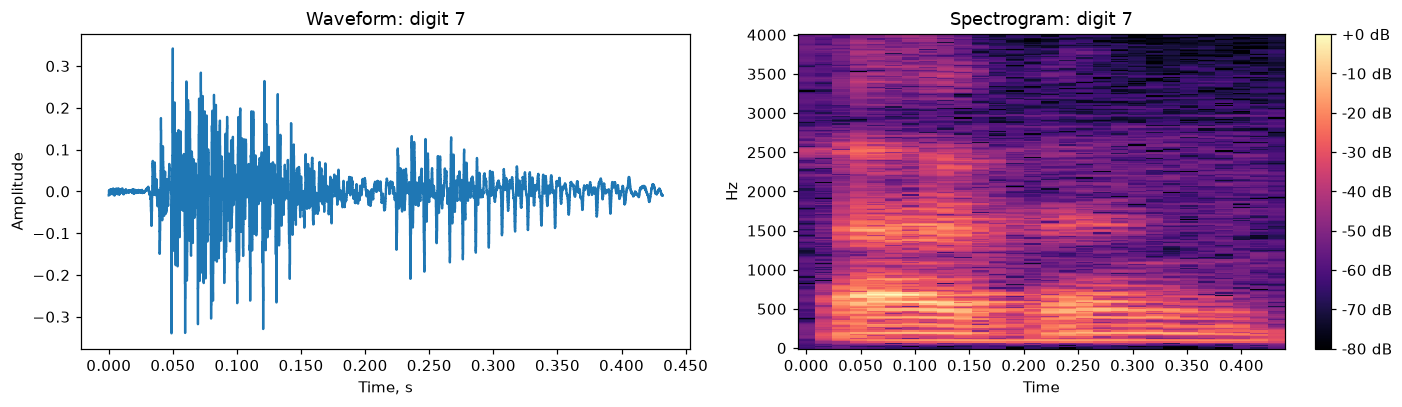

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

librosa.display.waveshow(signal, sr=sr, ax=axes[0], color="tab:blue")
axes[0].set(title="Waveform: digit 7", xlabel="Time, s", ylabel="Amplitude")

S_db = librosa.amplitude_to_db(np.abs(librosa.stft(signal, n_fft=512, hop_length=128)), ref=np.max)
img = librosa.display.specshow(S_db, sr=sr, hop_length=128, x_axis="time", y_axis="hz", ax=axes[1], cmap="magma")
axes[1].set(title="Spectrogram: digit 7")
fig.colorbar(img, ax=axes[1], format="%+.0f dB")
plt.tight_layout(); plt.show()

word is ~0.4 s. most energy below ~1500 Hz (vowels), high part is "s" in seven

MFCC = short description of sound close to how we hear. cut sound in small frames (16 ms) -> frequencies -> mel scale (ear hears low sounds better) -> log + DCT -> few numbers per frame.
first coefficients = general shape, last ones = small details

MFCC shape (coefficients, frames): (20, 28)


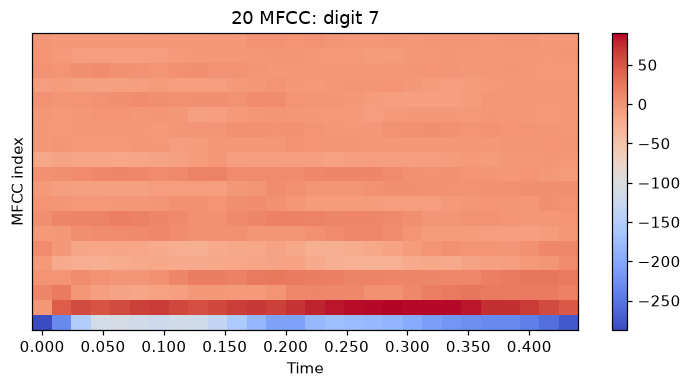

In [24]:
N_FFT, HOP, N_MELS = 512, 128, 40   # same settings for all experiments

def get_mfcc(path, n_mfcc):
    y, sr = librosa.load(path, sr=None)
    return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)

mfcc_example = get_mfcc(example.path, 20)
print("MFCC shape (coefficients, frames):", mfcc_example.shape)

fig, ax = plt.subplots(figsize=(8, 3.5))
img = librosa.display.specshow(mfcc_example, sr=sr, hop_length=HOP, x_axis="time", ax=ax, cmap="coolwarm")
ax.set(title="20 MFCC: digit 7", ylabel="MFCC index")
fig.colorbar(img, ax=ax)
plt.show()

2. train / test split by speaker

model must work for new people so split by speaker. 2 speakers for test, dont touch them until the end. 4 speakers for train and all search.
validation = leave one speaker out: train on 3, check on 4th, 4 times

In [25]:
TEST_SPEAKERS = ["theo", "yweweler"]

train_df = df[~df.speaker.isin(TEST_SPEAKERS)].reset_index(drop=True)
test_df  = df[df.speaker.isin(TEST_SPEAKERS)].reset_index(drop=True)

groups = train_df.speaker.values      # speaker = group for validation
y_train, y_test = train_df.digit.values, test_df.digit.values
cv = LeaveOneGroupOut()

print("Train speakers:", sorted(train_df.speaker.unique()), "->", len(train_df), "files")
print("Test speakers: ", sorted(test_df.speaker.unique()), "->", len(test_df), "files")
print("Common speakers:", set(train_df.speaker) & set(test_df.speaker))

Train speakers: ['george', 'jackson', 'lucas', 'nicolas'] -> 2000 files
Test speakers:  ['theo', 'yweweler'] -> 1000 files
Common speakers: set()


features

MFCC matrix is coefficients x frames, frames differ per file so I average over time to get fixed size vector.
`parts` = cut frames into equal parts and average each. parts=1 is normal average (baseline), parts=3 is start/middle/end so model knows order of sounds.
extract 40 MFCC once, n_mfcc=k is just first k rows (same numbers in librosa), so search is faster

In [26]:
MAX_MFCC = 40
mfcc_train = [get_mfcc(p, MAX_MFCC) for p in train_df.path]
mfcc_test  = [get_mfcc(p, MAX_MFCC) for p in test_df.path]

def make_features(mfcc_list, n_mfcc, parts=1):
    rows = []
    for m in mfcc_list:
        m = m[:n_mfcc]                                  # keep the first n_mfcc coefficients
        pieces = np.array_split(m, parts, axis=1)       # cut time into equal parts
        rows.append(np.concatenate([p.mean(axis=1) for p in pieces]))
    return np.array(rows)   # size = n_mfcc * parts

print("Done. Example vector size for 20 MFCC:", make_features(mfcc_train[:1], 20).shape[1])

Done. Example vector size for 20 MFCC: 20


3. baseline

KNN = take k closest examples and vote. uses distance so need StandardScaler.
random forest = many trees, each tree votes.
accuracy = % correct, macro F1 = F1 per digit then average

In [27]:
def baseline_knn():
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

def baseline_rf():
    return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)

def validate(model, X):
    """Leave-one-speaker-out validation on the train speakers."""
    res = cross_validate(model, X, y_train, groups=groups, cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    return res["test_accuracy"].mean(), res["test_f1_macro"].mean()

def test_score(model, X_tr, X_te):
    """Train on all train speakers, check on test speakers."""
    pred = model.fit(X_tr, y_train).predict(X_te)
    return accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro"), pred

In [28]:
X_train_20 = make_features(mfcc_train, 20)
X_test_20  = make_features(mfcc_test, 20)

baseline_rows = []
for name, model in [("Baseline KNN", baseline_knn()), ("Baseline RF", baseline_rf())]:
    val_acc, val_f1 = validate(model, X_train_20)
    baseline_rows.append({"Model": name, "Val Accuracy": val_acc, "Val Macro F1": val_f1})
pd.DataFrame(baseline_rows).round(3)

,Model,Val Accuracy,Val Macro F1
0,Baseline KNN,0.278,0.232
1,Baseline RF,0.313,0.257


validation is low bc model knows only 3 voices and gets new one. test results in part 7

4. searching for better MFCC

code tries all combos and keeps best (grid / stepwise search, option A):
- n_mfcc: 5, 8, 10, 13, 15, 20, 25, 30, 35, 40
- parts: 1 to 8

score = mean macro F1 of baseline KNN and baseline RF on speaker validation, so features good for both. takes few minutes

In [29]:
N_MFCC_LIST = [5, 8, 10, 13, 15, 20, 25, 30, 35, 40]
PARTS_LIST = [1, 2, 3, 4, 5, 6, 7, 8]

history = []
for parts in PARTS_LIST:
    for n in N_MFCC_LIST:
        X = make_features(mfcc_train, n, parts)
        _, f1_knn = validate(baseline_knn(), X)
        _, f1_rf  = validate(baseline_rf(), X)
        history.append({"n_mfcc": n, "parts": parts, "features": X.shape[1],
                        "KNN F1": f1_knn, "RF F1": f1_rf, "score": (f1_knn + f1_rf) / 2})

history = pd.DataFrame(history)
best_mfcc = history.loc[history.score.idxmax()]
BEST_N, BEST_PARTS = int(best_mfcc.n_mfcc), int(best_mfcc.parts)
print(f"Best MFCC: n_mfcc={BEST_N}, parts={BEST_PARTS}, features={int(best_mfcc.features)}")
history.sort_values("score", ascending=False).round(3).head(10)

Best MFCC: n_mfcc=15, parts=5, features=75


,n_mfcc,parts,features,KNN F1,RF F1,score
44,15,5,75,0.426,0.514,0.470
74,15,8,120,0.423,0.514,0.469
63,13,7,91,0.460,0.476,0.468
34,15,4,60,0.422,0.504,0.463
73,13,8,104,0.425,0.499,0.462
64,15,7,105,0.432,0.482,0.457
43,13,5,65,0.426,0.479,0.453
42,10,5,50,0.444,0.456,0.450
62,10,7,70,0.437,0.462,0.450
65,20,7,140,0.394,0.501,0.447


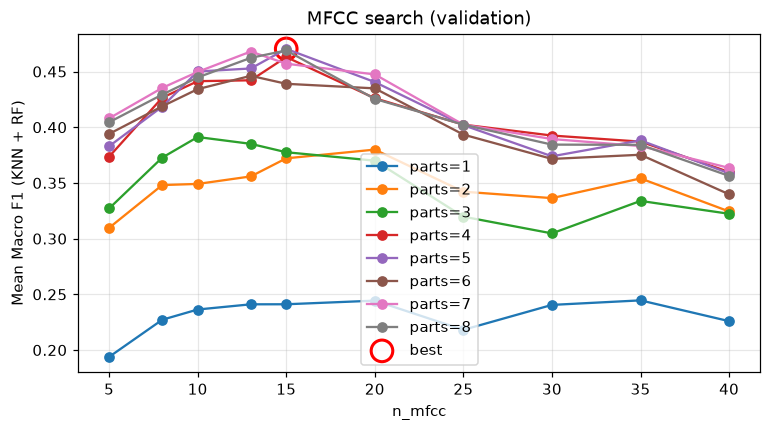

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
for parts, part in history.groupby("parts"):
    ax.plot(part.n_mfcc, part.score, marker="o", label=f"parts={parts}")
ax.scatter(BEST_N, best_mfcc.score, s=200, facecolors="none", edgecolors="red", linewidths=2, label="best")
ax.set(title="MFCC search (validation)", xlabel="n_mfcc", ylabel="Mean Macro F1 (KNN + RF)")
ax.grid(alpha=0.3); ax.legend()
plt.show()

In [31]:
X_train_best = make_features(mfcc_train, BEST_N, BEST_PARTS)
X_test_best  = make_features(mfcc_test, BEST_N, BEST_PARTS)
MFCC_TEXT = f"{BEST_N} MFCC, {BEST_PARTS} parts"
print("Selected:", MFCC_TEXT, "->", X_train_best.shape[1], "features")

Selected: 15 MFCC, 5 parts -> 75 features


5. searching for better KNN

KNN is fast so GridSearchCV over all combos: n_neighbors odd 1-31, weights uniform/distance, metric euclidean/manhattan

In [32]:
knn_grid = {
    "kneighborsclassifier__n_neighbors": list(range(1, 32, 2)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__metric": ["euclidean", "manhattan"],
}
knn_search = GridSearchCV(baseline_knn(), knn_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
knn_search.fit(X_train_best, y_train, groups=groups)

best_knn_params = {k.split("__")[1]: v for k, v in knn_search.best_params_.items()}
print("Combinations tested:", len(knn_search.cv_results_["params"]))
print("Best KNN:", best_knn_params)
print("Best validation Macro F1:", round(knn_search.best_score_, 3))

Combinations tested: 64
Best KNN: {'metric': 'euclidean', 'n_neighbors': 13, 'weights': 'uniform'}
Best validation Macro F1: 0.437


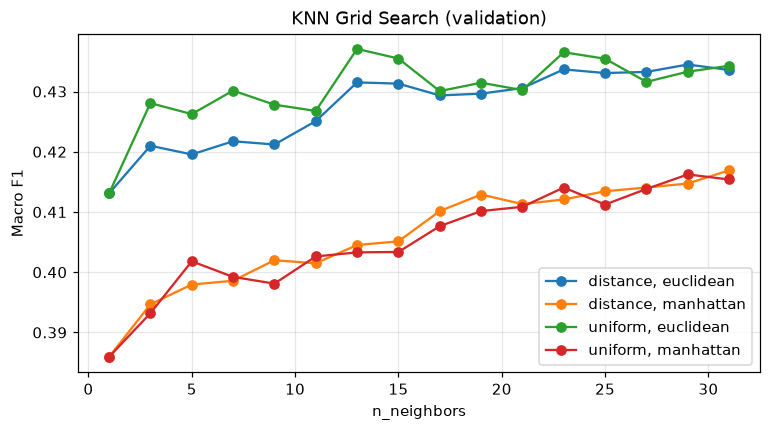

In [33]:
res = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(8, 4))
for (w, m), part in res.groupby(["param_kneighborsclassifier__weights", "param_kneighborsclassifier__metric"]):
    ax.plot(part.param_kneighborsclassifier__n_neighbors, part.mean_test_score, marker="o", label=f"{w}, {m}")
ax.set(title="KNN Grid Search (validation)", xlabel="n_neighbors", ylabel="Macro F1")
ax.grid(alpha=0.3); ax.legend()
plt.show()

6. searching for better random forest

RF has more params, full grid too big, so RandomizedSearchCV with 40 random combos. n_estimators = trees, max_depth = tree depth, min_samples_split/leaf = against overfitting, max_features = features per split

In [34]:
rf_space = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5],
}
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=SEED), rf_space, n_iter=40,
                               cv=cv, scoring="f1_macro", random_state=SEED, n_jobs=-1)
rf_search.fit(X_train_best, y_train, groups=groups)

print("Best RF:", rf_search.best_params_)
print("Best validation Macro F1:", round(rf_search.best_score_, 3))

Best RF: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best validation Macro F1: 0.532


In [35]:
top = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
top = top[["param_" + p for p in rf_space] + ["mean_test_score"]].head(10)
top.columns = list(rf_space) + ["val Macro F1"]
top.round(3)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,val Macro F1
21,200,20,10,1,sqrt,0.532
18,200,None,10,1,sqrt,0.530
25,500,30,10,1,sqrt,0.529
13,300,30,10,1,sqrt,0.527
14,500,None,2,1,log2,0.521
23,500,None,5,2,log2,0.519
3,300,None,5,4,sqrt,0.519
4,100,30,10,4,log2,0.517
28,300,20,10,4,sqrt,0.513
24,200,30,2,1,sqrt,0.508


7. final comparison

only now use test speakers (theo, yweweler). train on all 4 train speakers, test on these 2

In [36]:
best_knn = knn_search.best_estimator_
best_rf  = rf_search.best_estimator_
knn_text = f"k={best_knn_params['n_neighbors']}, {best_knn_params['weights']}, {best_knn_params['metric']}"
rf_text  = ", ".join(f"{k}={v}" for k, v in rf_search.best_params_.items())

systems = [
    ("Baseline KNN",                 "20 MFCC, 1 part", "KNN, k=5",       baseline_knn(), X_train_20,   X_test_20),
    ("Optimized MFCC + baseline KNN", MFCC_TEXT,      "KNN, k=5",       baseline_knn(), X_train_best, X_test_best),
    ("Best KNN",                      MFCC_TEXT,      knn_text,         best_knn,       X_train_best, X_test_best),
    ("Baseline RF",                  "20 MFCC, 1 part", "RF, 100 trees",  baseline_rf(),  X_train_20,   X_test_20),
    ("Optimized MFCC + baseline RF",  MFCC_TEXT,      "RF, 100 trees",  baseline_rf(),  X_train_best, X_test_best),
    ("Best Random Forest",            MFCC_TEXT,      rf_text,          best_rf,        X_train_best, X_test_best),
]

results, predictions = [], {}
for name, mfcc_cfg, model_cfg, model, X_tr, X_te in systems:
    acc, f1, pred = test_score(model, X_tr, X_te)
    predictions[name] = pred
    results.append({"System": name, "MFCC configuration": mfcc_cfg, "Model configuration": model_cfg,
                    "Test Accuracy": round(acc, 3), "Macro F1": round(f1, 3)})

results = pd.DataFrame(results)
results

,System,MFCC configuration,Model configuration,Test Accuracy,Macro F1
0,Baseline KNN,"20 MFCC, 1 part","KNN, k=5",0.339,0.300
1,Optimized MFCC + baseline KNN,"15 MFCC, 5 parts","KNN, k=5",0.681,0.695
2,Best KNN,"15 MFCC, 5 parts","k=13, uniform, euclidean",0.692,0.708
3,Baseline RF,"20 MFCC, 1 part","RF, 100 trees",0.601,0.583
4,Optimized MFCC + baseline RF,"15 MFCC, 5 parts","RF, 100 trees",0.857,0.849
5,Best Random Forest,"15 MFCC, 5 parts","n_estimators=200, min_samples_split=10, min_sa...",0.859,0.851


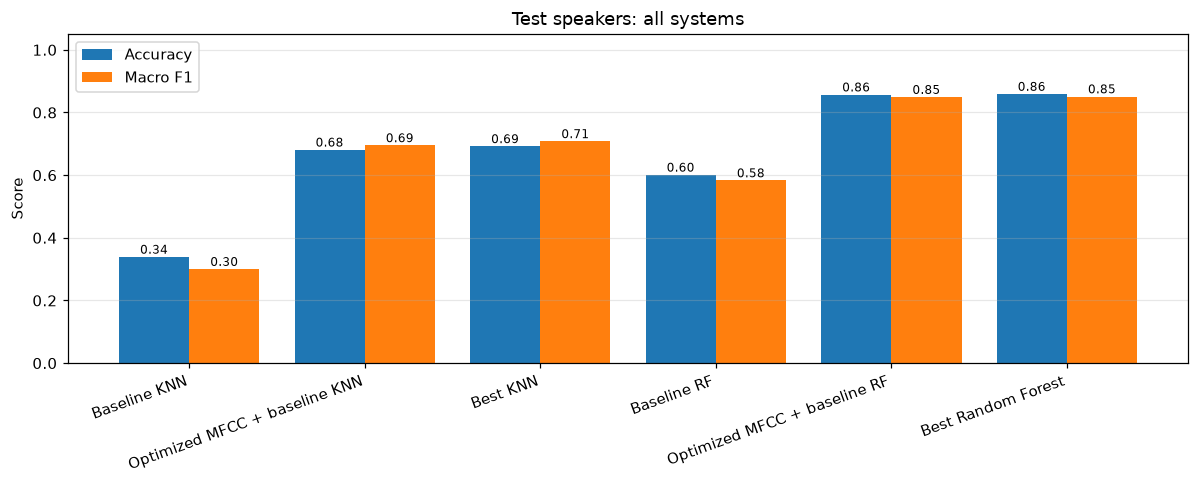

In [37]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(results))
ax.bar(x - 0.2, results["Test Accuracy"], width=0.4, label="Accuracy")
ax.bar(x + 0.2, results["Macro F1"], width=0.4, label="Macro F1")
for i, v in enumerate(results["Test Accuracy"]):
    ax.text(i - 0.2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
for i, v in enumerate(results["Macro F1"]):
    ax.text(i + 0.2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, results.System, rotation=20, ha="right")
ax.set(ylim=(0, 1.05), ylabel="Score", title="Test speakers: all systems")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

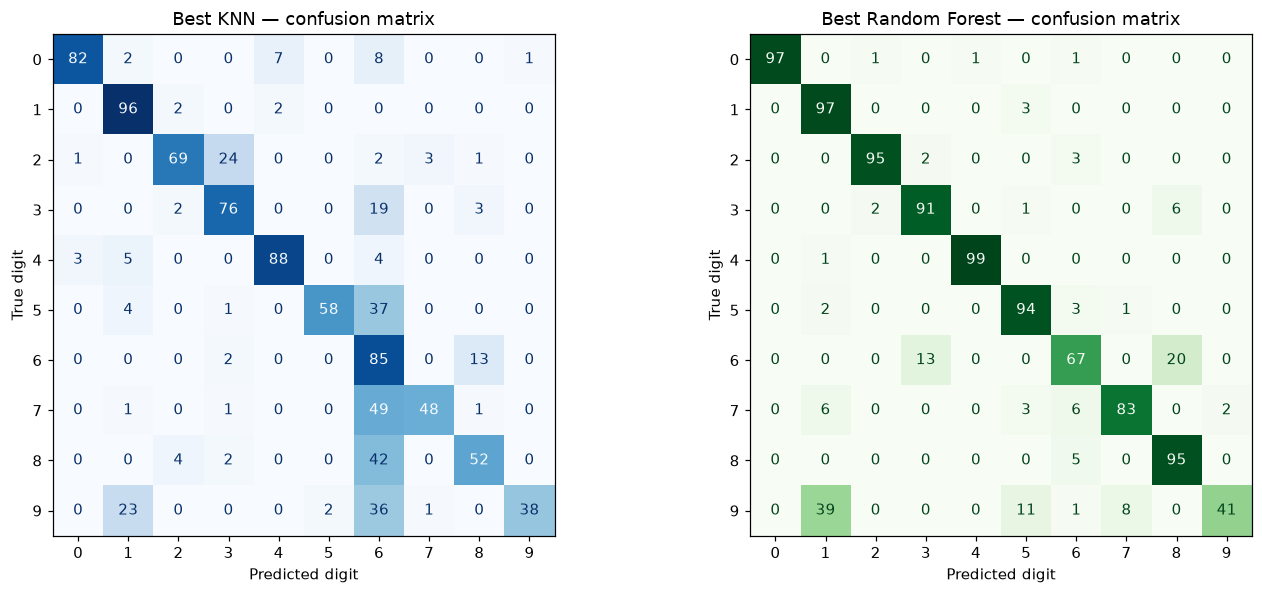

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name, cmap in zip(axes, ["Best KNN", "Best Random Forest"], ["Blues", "Greens"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], ax=ax, cmap=cmap, colorbar=False)
    ax.set(title=f"{name} — confusion matrix", xlabel="Predicted digit", ylabel="True digit")
plt.tight_layout(); plt.show()

In [39]:
best_row = results.loc[results["Macro F1"].idxmax()]
print("Best overall:", best_row.System, "| Accuracy:", best_row["Test Accuracy"], "| Macro F1:", best_row["Macro F1"])
for model in ["KNN", "RF"]:
    base = results[results.System == f"Baseline {model}"]["Macro F1"].item()
    opt  = results[results.System == f"Optimized MFCC + baseline {model}"]["Macro F1"].item()
    print(f"{model}: 20 MFCC -> {base:.3f}, optimized MFCC -> {opt:.3f}  (change {opt - base:+.3f})")

Best overall: Best Random Forest | Accuracy: 0.859 | Macro F1: 0.851
KNN: 20 MFCC -> 0.300, optimized MFCC -> 0.695  (change +0.395)
RF: 20 MFCC -> 0.583, optimized MFCC -> 0.849  (change +0.266)


which search I used and why

- MFCC: grid / stepwise over n_mfcc and parts, 80 configs. space is small so try all
- KNN: GridSearchCV, 64 combos, KNN is fast
- RF: RandomizedSearchCV, 40 combos, space is big
- all choices by leave one speaker out on train speakers, test not used

conclusion

best MFCC: 15 coefficients, 5 time parts = 75 features (best of 80)
best KNN: k=13, uniform, euclidean -> macro F1 0.708 (baseline 0.300)
best RF: 200 trees, max_depth=20, min_samples_split=10, min_samples_leaf=1, max_features=sqrt -> macro F1 0.851 (baseline 0.583)
best overall: random forest, accuracy 0.859, macro F1 0.851

most gain from MFCC search not from tuning. one average loses order of sounds, 5 parts keep it. same models KNN 0.300 -> 0.695, RF 0.583 -> 0.849. tuning added little (KNN +0.013, RF +0.002).
RF better than KNN I think bc it picks useful features itself, KNN uses all 75 the same.
common mistakes: 9 as 1 (both have "n" sound), 6 as 8 or 3. KNN says 6 too often.
validation lower than test bc in validation model learns from 3 voices, in test from 4